# A cell cycle clock from RNA and morphology in the Cytos CRISPR screen

This notebook explains the shared dataset, how we built a cell cycle clock from its RNA, and how to use that clock in a dataset that has only morphology. Each cell in the dataset has cell painting, protein stains, a CRISPR guide and RNA measured together, so we can learn the clock from RNA and then predict it from images.

The sections cover the following steps.

1. What the file contains and how to load it.
2. The two RNA models, cycleVI and DrVI.
3. The evidence that the clock follows the cell cycle.
4. The ranking of morphology features against the clock.
5. How to train a morphology clock on the features your dataset shares with ours, with a worked example.

## Summary for users

- **The RNA clock is well supported in its order of events.** DNA content, which the model never saw, rises and then drops at the point where cells appear to divide. Exact angles aren't settled.
- **The morphology clock is coarse.** It mainly separates cells with high DNA content (S and G2) from cells with low DNA content (G1). Use it to assign those broad states, and not as a fine position around the cycle.
- **Accuracy on unseen wells of this dataset:** with 100 features and balanced gradient boosting, the median error is 40 degrees over all cells and 44 degrees when every part of the cycle counts equally. A random guess gives 90 degrees. Nucleus features provide most of the accuracy.
- **Transfer to other datasets is untested.** Check any result against DNA content and known perturbations.


## 1. The dataset

The file is `cytos_multiomics_cycle_v1.h5mu` (1.9 GB). It's public at `https://exampledata.scverse.org/sbi2-cytodata/multiomics/cytos_multiomics_cycle_v1.h5mu`, and a copy is on the team VM at `/srv/team/data/multiomics/`. The next cell downloads the file if it isn't already in the working folder or on the VM. Loading it took 19 seconds and 4.3 GB of memory on the VM.

In [1]:
import shutil
import urllib.request
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

NAME = "cytos_multiomics_cycle_v1.h5mu"
URL = f"https://exampledata.scverse.org/sbi2-cytodata/multiomics/{NAME}"
path = next((p for p in [Path(NAME), Path("/srv/team/data/multiomics") / NAME] if p.exists()), Path(NAME))
if not path.exists():
    with urllib.request.urlopen(urllib.request.Request(URL, headers={"User-Agent": "curl/8"})) as response, open(path, "wb") as out:
        shutil.copyfileobj(response, out)
mdata = md.read_h5mu(path)
rna, img = mdata["rna"], mdata["imaging"]
obs = mdata.obs
mdata

MuData object with n_obs × n_vars = 206091 × 56108
  obs:	'Well', 'Cell', 'tile_id', 'condition', 'guide', 'target_gene', 'guide_confidence', 'guide_assigned', 'rna_total_counts', 'rna_n_genes', 'rna_pct_mt', 'qc_low_rna', 'qc_guide_unassigned', 'qc_spatial_artifact', 'qc_imaging_nan', 'qc_no_nucleus', 'Metadata_Plate', 'Metadata_Well', 'Metadata_ImageID', 'Metadata_ObjectType', 'Metadata_ObjectNumber', 'Metadata_Perturbation', 'Metadata_Row', 'Metadata_Col', 'Metadata_Control_Type', 'Metadata_Control', 'qc_n_nan_features', 'qc_nan_fraction', 'qc_is_border', 'qc_area_outlier', 'qc_fail', 'qc_outlier', 'qc_outlier_score', 'cycle_position_deg', 'cycle_radius', 'S_score', 'G2M_score', 'phase_scanpy'
  uns:	'description'
  3 modalities
    rna:	206091 × 54949
      var:	'gene_id', 'gene_type', 'seqname', 'start', 'end', 'strand', 'hgnc_id'
      uns:	'mantispy', 'metadata_attrs', 'spatial_artifact_params'
      obsm:	'X_cyclevi_cycle', 'X_cyclevi_other', 'X_drvi', 'X_drvi_well', 'spatial'


The object has three parts that share the same cells, in the same order. `mdata.obs` holds what describes a cell, including its clock position. All cells passed QC, so the 52,805 cells that failed are not in this file, and the QC columns are kept for reference.

In [2]:
pd.DataFrame([
    {"part": "rna", "contains": "RNA counts in .X, nuclear counts in layers['nuclear']", "size": f"{rna.n_vars} genes"},
    {"part": "rna.obsm", "contains": "X_cyclevi_cycle, X_cyclevi_other, X_drvi, X_drvi_well", "size": "embeddings"},
    {"part": "imaging", "contains": "scaled features in .X, original values in layers['raw']", "size": f"{img.n_vars} features"},
    {"part": "imaging.var", "contains": "channel, modality, clock ranking in clock_* columns", "size": ""},
    {"part": "guides", "contains": "guide counts", "size": f"{mdata['guides'].n_vars} guides"},
    {"part": "obs", "contains": "well, condition, guide, target_gene, qc_*, cycle_position_deg, cycle_radius, S_score, G2M_score", "size": f"{mdata.n_obs} cells"},
]).style.hide(axis="index")

part,contains,size
rna,"RNA counts in .X, nuclear counts in layers['nuclear']",54949 genes
rna.obsm,"X_cyclevi_cycle, X_cyclevi_other, X_drvi, X_drvi_well",embeddings
imaging,"scaled features in .X, original values in layers['raw']",1131 features
imaging.var,"channel, modality, clock ranking in clock_* columns",
guides,guide counts,28 guides
obs,"well, condition, guide, target_gene, qc_*, cycle_position_deg, cycle_radius, S_score, G2M_score",206091 cells


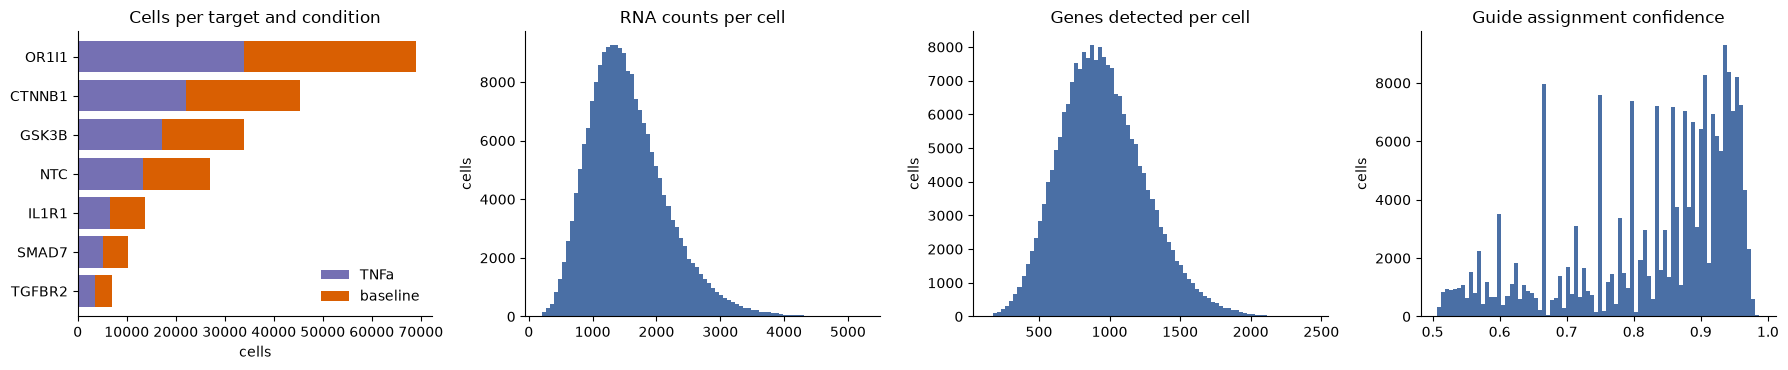

modality    channel                  
background  Actin                        10
            Cell-Membrane                10
            ERK1_ERK2                    10
            Mitochondria                 10
            Mouse_IgG                    10
            Nucleus                      10
            Phospho-ERK1_Phospho-ERK2    10
            Phospho-HSP27                10
            Phospho-p38                  10
            Rabbit_IgG                   10
            NaN                          40
cell_paint  Actin                        97
            Cell-Membrane                97
            Mitochondria                 97
            Nucleus                      97
control     Mouse_IgG                    97
            Rabbit_IgG                   97
protein     ERK1_ERK2                    97
            Phospho-ERK1_Phospho-ERK2    97
            Phospho-HSP27                97
            Phospho-p38                  97
shape       NaN                       

In [3]:
targets, conditions, wells = obs["target_gene"].astype(str).values, obs["condition"].astype(str).values, obs["Well"].astype(str).values
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
pd.crosstab(targets, conditions).sort_values("baseline").plot.barh(stacked=True, ax=axes[0], color=["#7570b3", "#d95f02"], width=0.8)
axes[0].set(title="Cells per target and condition", xlabel="cells", ylabel="")
axes[0].legend(frameon=False)
for ax, column, title in zip(axes[1:], ["rna_total_counts", "rna_n_genes", "guide_confidence"], ["RNA counts per cell", "Genes detected per cell", "Guide assignment confidence"]):
    ax.hist(obs[column], bins=80, color="#4a6fa5")
    ax.set(title=title, ylabel="cells")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(img.var.groupby(["modality", "channel"], observed=True, dropna=False).size().to_string())

The screen is A549 cells with and without TNFa, across 12 wells. There are six target genes and non-targeting (NTC) controls, with 4 guides each. OR1I1 is an olfactory receptor that shouldn't be expressed in A549, so it acts as a second control. Cells carry about 1,500 RNA counts each, which is low, so single cells are noisy.

## 2. The RNA models

We ran two models on raw RNA counts. Neither model saw images, guides or conditions.

- **cycleVI** learns a circular position for each cell in the cell cycle (`X_cyclevi_cycle`, two dimensions), and a separate embedding with the cycle removed (`X_cyclevi_other`). We ran 400 epochs without a batch covariate. Its angle has no fixed start, so we set 0 degrees at the peak of the S score and made the direction run towards the G2/M peak. That gives `cycle_position_deg`.
- **DrVI** learns 32 dimensions in which separate biological signals tend to land in separate dimensions (`X_drvi`). `X_drvi_well` used well as a covariate. Wells are nested within condition, so that version could reduce the TNFa signal.

The plots below show 40,000 random cells. The clock's colour map wraps around, because 0 and 360 degrees are the same point.

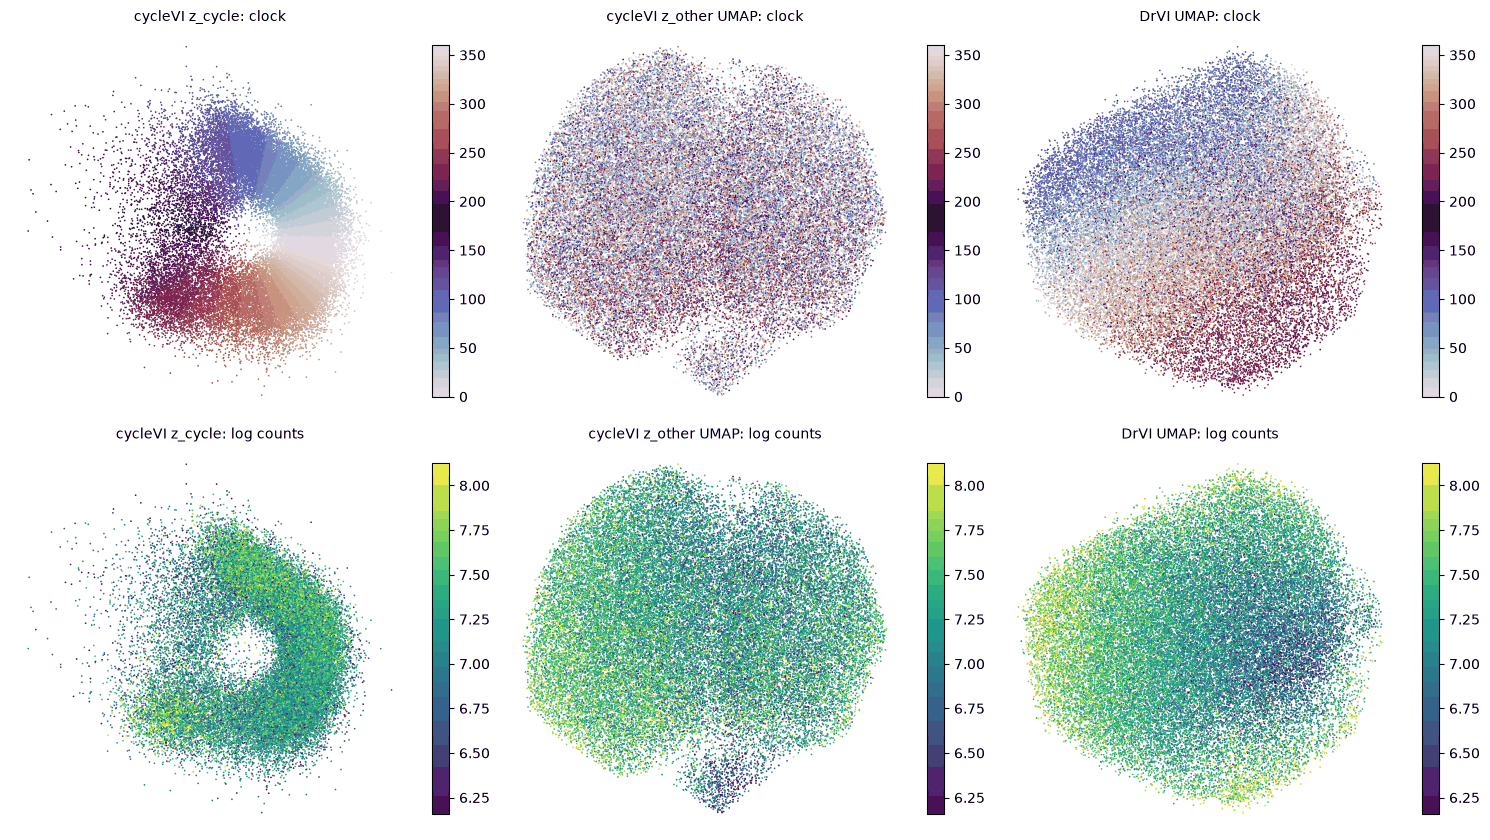

In [4]:
sample = np.sort(np.random.default_rng(0).choice(mdata.n_obs, 40_000, replace=False))
clock_deg = obs["cycle_position_deg"].values
log_counts = np.log1p(obs["rna_total_counts"].values)


def embed(values):
    a = ad.AnnData(X=np.zeros((len(values), 1), dtype=np.float32), obsm={"X_rep": np.asarray(values, dtype=np.float32)})
    sc.pp.neighbors(a, use_rep="X_rep", transformer="sklearn")
    sc.tl.umap(a, random_state=0)
    return a.obsm["X_umap"]


def plot_points(ax, xy, colour, title, cmap="viridis", limits=None):
    order = np.random.default_rng(1).permutation(len(xy))
    limits = limits or tuple(np.quantile(colour, [0.01, 0.99]))
    points = ax.scatter(*xy[order].T, c=colour[order], s=1.5, linewidths=0, cmap=cmap, vmin=limits[0], vmax=limits[1], rasterized=True)
    plt.colorbar(points, ax=ax, fraction=0.04)
    ax.set_title(title, fontsize=10)
    ax.set(xticks=[], yticks=[])
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)


cycle_xy = np.asarray(rna.obsm["X_cyclevi_cycle"])[sample]
drvi_umap, other_umap = embed(rna.obsm["X_drvi"][sample]), embed(rna.obsm["X_cyclevi_other"][sample])
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
plot_points(axes[0, 0], cycle_xy, clock_deg[sample], "cycleVI z_cycle: clock", "twilight", (0, 360))
plot_points(axes[0, 1], other_umap, clock_deg[sample], "cycleVI z_other UMAP: clock", "twilight", (0, 360))
plot_points(axes[0, 2], drvi_umap, clock_deg[sample], "DrVI UMAP: clock", "twilight", (0, 360))
plot_points(axes[1, 0], cycle_xy, log_counts[sample], "cycleVI z_cycle: log counts")
plot_points(axes[1, 1], other_umap, log_counts[sample], "cycleVI z_other UMAP: log counts")
plot_points(axes[1, 2], drvi_umap, log_counts[sample], "DrVI UMAP: log counts")
plt.tight_layout()
plt.show()

Three things are visible. First, `z_cycle` arranges cells around a ring in clock order. Second, the clock colours mix in `z_other`, which is what removing the cycle should do. Third, the DrVI UMAP still shows the clock because the cycle is inside its dimensions, and we can read which ones below. Single-cell UMAPs here show one continuous cloud instead of separate clusters, because this is one cell line with low RNA counts and mostly weak knockouts. Averages per guide and well separate knockouts much better than single cells do.

In [5]:
def well_centre(values):
    frame = pd.DataFrame(values)
    return (frame - frame.groupby(wells).transform("mean")).to_numpy()


angle = np.radians(clock_deg)
drvi = np.asarray(rna.obsm["X_drvi"])
d, c = well_centre(np.column_stack([np.sin(angle), np.cos(angle)])), well_centre(drvi)
clock_share = pd.Series(((d @ np.linalg.lstsq(d, c, rcond=None)[0]) ** 2).sum(0) / (c**2).sum(0), name="share of variance explained by the clock").sort_values(ascending=False)
clock_share.head(5).round(3)

31    0.704
5     0.469
0     0.178
11    0.082
25    0.080
Name: share of variance explained by the clock, dtype: float64

## 3. Evidence that the clock follows the cell cycle

The clock came only from RNA, so measurements from images test it independently. The next figure follows genes and image measurements around the circle. DNA content should rise during S phase and drop when cells divide, and known genes should peak in the known order.

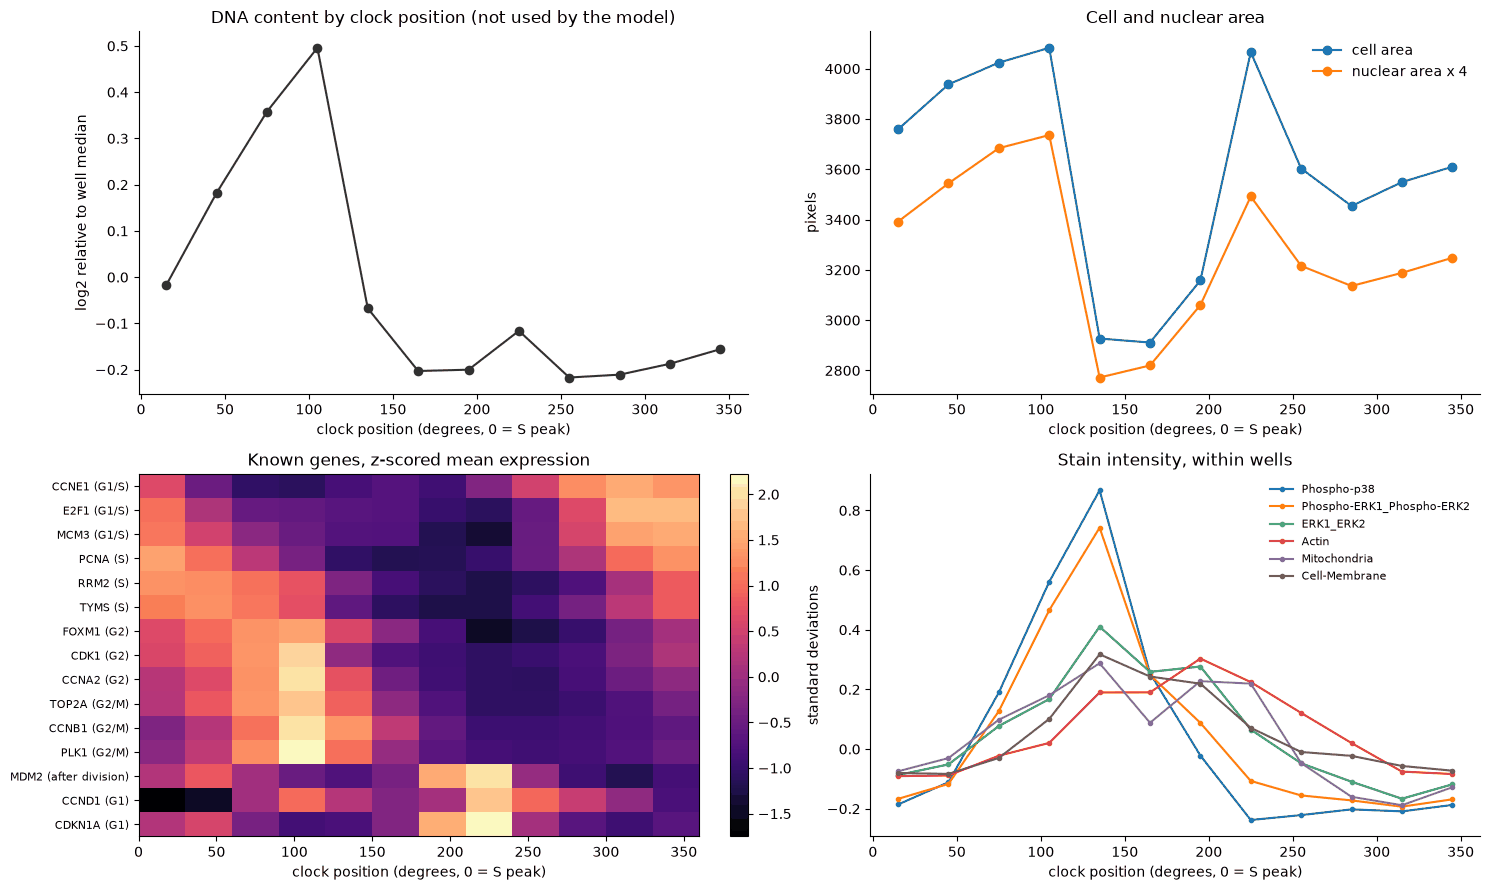

In [6]:
raw = pd.DataFrame(img.layers["raw"], columns=img.var_names)
dna = ((raw["Nucleus_Nuclear"] - raw["Bkg_Nucleus_Nuclear"]) * raw["NuclearArea"]).clip(lower=1)
dna = (np.log2(dna) - np.log2(dna).groupby(wells).transform("median")).values
EDGES = np.arange(0, 361, 30)
centres = EDGES[:-1] + 15
bins = np.digitize(clock_deg, EDGES[1:-1])


def by_bin(values):
    return pd.Series(np.asarray(values)).groupby(bins).median().values


def within_well_z(values):
    frame = pd.DataFrame(values)
    grouped = frame.groupby(wells)
    return ((frame - grouped.transform("mean")) / grouped.transform("std").replace(0, 1)).to_numpy(np.float32)


GENES = {"CCNE1": "G1/S", "E2F1": "G1/S", "MCM3": "G1/S", "PCNA": "S", "RRM2": "S", "TYMS": "S", "FOXM1": "G2", "CDK1": "G2", "CCNA2": "G2", "TOP2A": "G2/M", "CCNB1": "G2/M", "PLK1": "G2/M", "MDM2": "after division", "CCND1": "G1", "CDKN1A": "G1"}
counts = rna[:, list(GENES)].X.toarray().astype(np.float32)
expression = np.log1p(counts / obs["rna_total_counts"].values[:, None] * 1e4)
smooth = pd.DataFrame(expression, columns=list(GENES)).groupby(bins).mean()
smooth = (smooth - smooth.mean()) / smooth.std()
smooth = smooth.loc[:, smooth.idxmax().map(lambda b: (b - 9) % 12).sort_values().index]
stains = {s: f"Intensity_MedianIntensity_{s}" for s in ["Phospho-p38", "Phospho-ERK1_Phospho-ERK2", "ERK1_ERK2", "Actin", "Mitochondria", "Cell-Membrane"]}
stain_table = pd.DataFrame(within_well_z(raw[list(stains.values())].to_numpy()), columns=list(stains)).groupby(bins).mean()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].plot(centres, by_bin(dna), marker="o", color="#333333")
axes[0, 0].set(title="DNA content by clock position (not used by the model)", ylabel="log2 relative to well median")
axes[0, 1].plot(centres, by_bin(raw["Area"]), marker="o", color="#1f77b4", label="cell area")
axes[0, 1].plot(centres, by_bin(raw["NuclearArea"]) * 4, marker="o", color="#ff7f0e", label="nuclear area x 4")
axes[0, 1].set(title="Cell and nuclear area", ylabel="pixels")
axes[0, 1].legend(frameon=False)
image = axes[1, 0].imshow(smooth.T.values, aspect="auto", cmap="magma", extent=[0, 360, len(smooth.columns), 0])
axes[1, 0].set_yticks(np.arange(len(smooth.columns)) + 0.5, [f"{g} ({GENES[g]})" for g in smooth.columns], fontsize=8)
axes[1, 0].set(title="Known genes, z-scored mean expression")
plt.colorbar(image, ax=axes[1, 0], fraction=0.03)
for stain in stain_table:
    axes[1, 1].plot(centres, stain_table[stain], marker="o", markersize=3, label=stain)
axes[1, 1].set(title="Stain intensity, within wells", ylabel="standard deviations")
axes[1, 1].legend(frameon=False, fontsize=8)
for ax in axes.ravel():
    ax.set_xlabel("clock position (degrees, 0 = S peak)")
for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

DNA content rises to its highest point at 90 to 120 degrees and then drops between 120 and 150 degrees, together with cell area, nuclear area and RNA depth. Dividing cells lose all four at once, so we read that step as the transition from G2/M to early G1. The genes appear in the known order: G1/S genes first, then S genes, FOXM1 and CDK1, then the G2/M genes. MDM2 and CDKN1A follow after division, which suggests a p53 response in early G1. Phospho-p38 and phospho-ERK peak around division. All stains get brighter at that point, probably because cells round up, but these two rise about two to three times as much.

**Limits of the clock.** Training hadn't converged at 400 epochs, and a run corrected for well gave different angles (circular correlation 0.19). The order of events is well supported, but exact angles aren't. The clock's speed also isn't constant, so 30 degrees doesn't always mean the same amount of time.

## 4. Morphology features ranked against the clock

`imaging.var` has a clock ranking for all 409 morphology features, with protein stains left out. The same table is in the repository as `results/clock_morphology_features.csv`. The main columns are as follows.

- `clock_r2` is the share of the feature's variance within wells that the clock explains.
- `clock_rank` orders features by `clock_r2`, and `clock_rank_nonredundant` keeps only the best feature in each group of highly correlated features (absolute correlation above about 0.9). Use the nonredundant rank to pick a panel.
- `clock_peak_deg` is the clock position at which the feature is highest.
- `clock_high_certainty` is True if the feature explains at least 1% in both conditions, peaks within 30 degrees of its overall peak in at least 90% of wells, and its peak moves by at most 30 degrees with TNFa.

Features: 409  high certainty: 157  nonredundant: 207


,channel,clock_r2,clock_peak_deg,clock_high_certainty,clock_rank,clock_rank_nonredundant
Nucleus_FractionAboveThreshold_Nuclear,Nucleus,0.108,96.128,True,1.0,1.0
Nucleus_Nuclear,Nucleus,0.105,111.867,True,2.0,2.0
Intensity_MaxIntensity_Nucleus,Nucleus,0.094,111.822,True,4.0,3.0
Intensity_IntegratedIntensity_Nucleus,Nucleus,0.072,107.350,True,15.0,4.0
Nucleus_NuclearRatio,Nucleus,0.072,292.966,True,16.0,5.0
Texture_Contrast_3_00_256_Nucleus,Nucleus,0.067,123.432,True,17.0,6.0
Texture_DifferenceVariance_3_02_256_Nucleus,Nucleus,0.065,288.713,True,21.0,7.0
Texture_DifferenceEntropy_3_02_256_Nucleus,Nucleus,0.064,119.047,True,23.0,8.0
Texture_DifferenceEntropy_3_00_256_Nucleus,Nucleus,0.063,119.228,True,24.0,9.0
Nucleus_FractionAboveThreshold_Cytoplasmic,Nucleus,0.051,117.016,True,29.0,10.0


,features,high_certainty,median_r2,best_r2
channel,,,,
Actin,97,18,0.0067,0.0243
Cell-Membrane,97,64,0.0130,0.0303
Mitochondria,97,10,0.0031,0.0323
Nucleus,97,65,0.0279,0.1083
none (shape),21,0,0.0037,0.0076


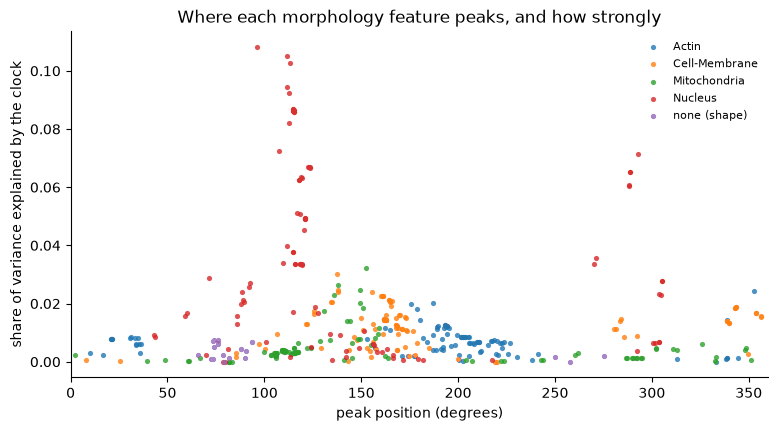

In [7]:
ranking = img.var[img.var["clock_rank"].notna()].copy()
ranking["channel"] = ranking["channel"].astype(object).fillna("none (shape)")
print("Features:", len(ranking), " high certainty:", int(ranking["clock_high_certainty"].sum()), " nonredundant:", int(ranking["clock_rank_nonredundant"].notna().sum()))
display(ranking.sort_values("clock_rank_nonredundant").head(15)[["channel", "clock_r2", "clock_peak_deg", "clock_high_certainty", "clock_rank", "clock_rank_nonredundant"]].round(3))
display(ranking.groupby("channel").agg(features=("clock_r2", "size"), high_certainty=("clock_high_certainty", "sum"), median_r2=("clock_r2", "median"), best_r2=("clock_r2", "max")).round(4))
fig, ax = plt.subplots(figsize=(9, 4.5))
for channel, group in ranking.groupby("channel"):
    ax.scatter(group["clock_peak_deg"], group["clock_r2"], s=14, label=channel, alpha=0.8, linewidths=0)
ax.set(xlabel="peak position (degrees)", ylabel="share of variance explained by the clock", title="Where each morphology feature peaks, and how strongly", xlim=(0, 360))
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Nucleus features dominate and mostly peak around 100 degrees, because they follow DNA content. Nucleus features alone therefore separate G2 from G1 well but say less about the other arcs. Features of the other stains peak at other positions, so they help to place cells around the rest of the circle.

## 5. Using the clock in a dataset with only morphology

The clock can't be computed in a dataset without RNA, but it can be predicted from images, by training on this dataset and applying the model to yours. The steps are as follows.

1. Find the features both datasets share. They need the same names and definitions, and this table uses CellProfiler-style names.
2. Pick a panel from those features, using `clock_rank_nonredundant`.
3. Z-score each feature within each well in both datasets, using original values. This removes differences in scale between datasets, assuming that the wells in both are mostly cycling cells.
4. Fit a ridge regression from the panel to the sine and cosine of the clock on this dataset.
5. Apply the model to your dataset and compute the position as arctan2(sine, cosine).

The two functions below do this. As a worked example, we treat 3 wells of each condition as the "other dataset", and train only on the remaining wells. The ranking itself used all wells, so these errors could be slightly optimistic.

In [8]:
def pick_panel(available, k, table=ranking):
    usable = table.loc[table.index.isin(available) & table["clock_rank_nonredundant"].notna()]
    return usable.sort_values("clock_rank_nonredundant").index[:k].tolist()


def z_by_well(values, well_labels):
    frame = pd.DataFrame(np.asarray(values, dtype=np.float32))
    grouped = frame.groupby(np.asarray(well_labels))
    z = (frame - grouped.transform("mean")) / grouped.transform("std").replace(0, 1)
    return np.nan_to_num(z.clip(-10, 10).to_numpy(np.float32))


def sector_weights(clock_degrees, width=30):
    # every part of the cycle counts equally, so the model can't win by ignoring rare phases
    sectors = np.floor(np.asarray(clock_degrees) / width).astype(int)
    return 1 / pd.Series(sectors).map(pd.Series(sectors).value_counts()).to_numpy()


def fit_morphology_clock(values, well_labels, clock_degrees, balanced=True):
    # values: original feature values, cells by panel features, from this dataset
    radians = np.radians(clock_degrees)
    weights = sector_weights(clock_degrees) if balanced else None
    return make_pipeline(StandardScaler(), Ridge(10)).fit(z_by_well(values, well_labels), np.column_stack([np.sin(radians), np.cos(radians)]), ridge__sample_weight=weights)


def predict_clock(model, values, well_labels):
    # values: the same features in the same order, from any dataset
    guess = model.predict(z_by_well(values, well_labels))
    return np.degrees(np.arctan2(guess[:, 0], guess[:, 1])) % 360


def median_error(predicted, true):
    return float(np.median(np.abs((predicted - true + 180) % 360 - 180)))


def balanced_error(predicted, true, width=30):
    # mean over parts of the cycle of each part's median error, so common phases can't hide rare ones
    error = np.abs((predicted - true + 180) % 360 - 180)
    return float(pd.Series(error).groupby(np.floor(true / width).astype(int)).median().mean())


rng = np.random.default_rng(0)
other_wells = np.concatenate([rng.permutation(np.unique(wells[conditions == c]))[:3] for c in np.unique(conditions)])
is_other = np.isin(wells, other_wells)
print("Wells treated as the other dataset:", sorted(other_wells))
print(len(pick_panel(ranking.index, 5)), pick_panel(ranking.index, 5))

Wells treated as the other dataset: ['B1', 'C2', 'D1', 'E2', 'F1', 'F2']
5 ['Nucleus_FractionAboveThreshold_Nuclear', 'Nucleus_Nuclear', 'Intensity_MaxIntensity_Nucleus', 'Intensity_IntegratedIntensity_Nucleus', 'Nucleus_NuclearRatio']


### What accuracy to expect for your stains

An ordinary fit looks accurate but is misleading, because most cells sit between 300 and 100 degrees and a model can do well by rarely predicting anything else. So we weight cells so that each 30 degree sector counts equally, and report two errors. The median error is over all cells. The balanced error is the mean of the median errors of the 12 sectors, so every part of the cycle counts equally. A random guess has an error of 90 degrees on both.

The first table compares the options on 20 and 100 features. The second shows the balanced fit by stain set and panel size.

In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor


def compare(k):
    panel = pick_panel(ranking.index, k)
    train_x, test_x = z_by_well(raw.loc[~is_other, panel].to_numpy(), wells[~is_other]), raw.loc[is_other, panel].to_numpy()
    true = clock_deg[is_other]
    rows = {}
    for label, balanced in {"ridge, ordinary": False, "ridge, balanced": True}.items():
        model = fit_morphology_clock(raw.loc[~is_other, panel].to_numpy(), wells[~is_other], clock_deg[~is_other], balanced=balanced)
        guess = predict_clock(model, test_x, wells[is_other])
        rows[label] = {"median error": median_error(guess, true), "balanced error": balanced_error(guess, true), "share predicted in 120 to 280 degrees": np.mean((guess > 120) & (guess < 280))}
    radians, weights = np.radians(clock_deg[~is_other]), sector_weights(clock_deg[~is_other])
    test_z = z_by_well(test_x, wells[is_other])
    guess = np.column_stack([HistGradientBoostingRegressor(random_state=0).fit(train_x, f(radians), sample_weight=weights).predict(test_z) for f in (np.sin, np.cos)])
    guess = np.degrees(np.arctan2(guess[:, 0], guess[:, 1])) % 360
    rows["gradient boosting, balanced"] = {"median error": median_error(guess, true), "balanced error": balanced_error(guess, true), "share predicted in 120 to 280 degrees": np.mean((guess > 120) & (guess < 280))}
    return pd.DataFrame(rows).T


print("Share of cells truly in 120 to 280 degrees:", round(float(np.mean((clock_deg[is_other] > 120) & (clock_deg[is_other] < 280))), 3))
pd.concat({k: compare(k) for k in [20, 100]}, names=["panel size"]).round(3)

Share of cells truly in 120 to 280 degrees: 0.219


median error  balanced error  \
panel size                                                             
20         ridge, ordinary                    43.647          73.002   
           ridge, balanced                    54.690          56.497   
           gradient boosting, balanced        46.841          50.009   
100        ridge, ordinary                    38.590          65.632   
           ridge, balanced                    49.398          52.866   
           gradient boosting, balanced        39.878          43.781   

                                        share predicted in 120 to 280 degrees  
panel size                                                                     
20         ridge, ordinary                                              0.016  
           ridge, balanced                                              0.305  
           gradient boosting, balanced                                  0.330  
100        ridge, ordinary                                              0.039  
           ridge, balanced                                              0.332  
           gradient boosting, balanced                                  0.339

In [10]:
channel_of = ranking["channel"]
STAIN_SETS = {
    "all morphology": ranking.index,
    "nucleus and shape": ranking.index[channel_of.isin(["Nucleus", "none (shape)"])],
    "nucleus only": ranking.index[channel_of == "Nucleus"],
    "no nucleus stain": ranking.index[channel_of != "Nucleus"],
    "shape only": ranking.index[channel_of == "none (shape)"],
    "actin only": ranking.index[channel_of == "Actin"],
    "membrane only": ranking.index[channel_of == "Cell-Membrane"],
    "mitochondria only": ranking.index[channel_of == "Mitochondria"],
}
SIZES = [1, 2, 5, 10, 20, 50, 100]
table = {}
for name, available in STAIN_SETS.items():
    row, balanced_row = {}, {}
    for k in SIZES:
        panel = pick_panel(available, k)
        if len(panel) < k:
            continue
        model = fit_morphology_clock(raw.loc[~is_other, panel].to_numpy(), wells[~is_other], clock_deg[~is_other])
        row[k] = balanced_error(predict_clock(model, raw.loc[is_other, panel].to_numpy(), wells[is_other]), clock_deg[is_other])
    table[name] = row
accuracy = pd.DataFrame(table).T.round(1)
accuracy.columns.name = "balanced error by panel size"
accuracy

balanced error by panel size,1,2,5,10,20,50,100
all morphology,83.8,57.2,54.7,55.8,56.5,54.7,52.9
nucleus and shape,83.8,57.2,54.7,55.8,56.8,55.3,NaN
nucleus only,83.8,57.2,54.7,55.8,56.8,55.4,NaN
no nucleus stain,85.4,73.4,68.8,65.1,66.1,66.6,65.5
shape only,70.0,70.0,77.6,78.5,NaN,NaN,NaN
actin only,62.0,64.3,65.5,67.8,68.7,68.1,NaN
membrane only,70.5,62.0,66.5,68.0,69.3,NaN,NaN
mitochondria only,85.4,78.7,77.8,75.6,74.5,NaN,NaN


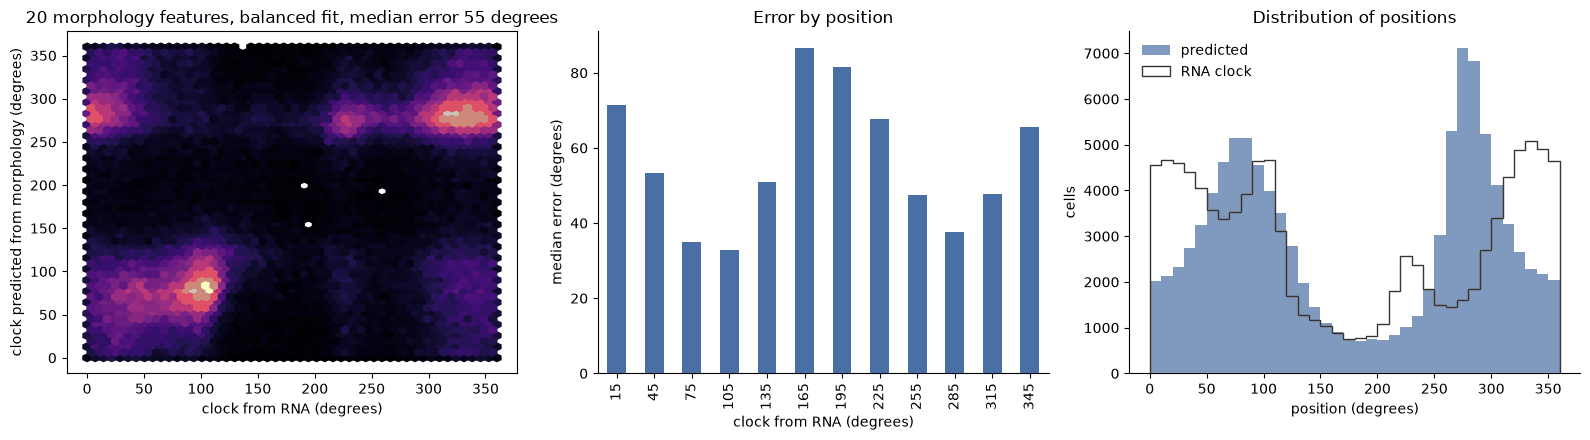

,CTNNB1,GSK3B,IL1R1,NTC,OR1I1,SMAD7,TGFBR2,TNFa,baseline
median error (degrees),51.9,56.7,55.0,54.6,54.9,55.7,62.0,56.3,53.2


,channel,clock_r2,clock_peak_deg,clock_high_certainty
Nucleus_FractionAboveThreshold_Nuclear,Nucleus,0.108,96.128,True
Nucleus_Nuclear,Nucleus,0.105,111.867,True
Intensity_MaxIntensity_Nucleus,Nucleus,0.094,111.822,True
Intensity_IntegratedIntensity_Nucleus,Nucleus,0.072,107.350,True
Nucleus_NuclearRatio,Nucleus,0.072,292.966,True
Texture_Contrast_3_00_256_Nucleus,Nucleus,0.067,123.432,True
Texture_DifferenceVariance_3_02_256_Nucleus,Nucleus,0.065,288.713,True
Texture_DifferenceEntropy_3_02_256_Nucleus,Nucleus,0.064,119.047,True
Texture_DifferenceEntropy_3_00_256_Nucleus,Nucleus,0.063,119.228,True
Nucleus_FractionAboveThreshold_Cytoplasmic,Nucleus,0.051,117.016,True


In [11]:
panel_20 = pick_panel(ranking.index, 20)
model = fit_morphology_clock(raw.loc[~is_other, panel_20].to_numpy(), wells[~is_other], clock_deg[~is_other])
predicted = predict_clock(model, raw.loc[is_other, panel_20].to_numpy(), wells[is_other])
true = clock_deg[is_other]
error = np.abs((predicted - true + 180) % 360 - 180)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hexbin(true, predicted, gridsize=50, cmap="magma", mincnt=1)
axes[0].set(xlabel="clock from RNA (degrees)", ylabel="clock predicted from morphology (degrees)", title=f"20 morphology features, balanced fit, median error {np.median(error):.0f} degrees")
pd.Series(error).groupby(np.digitize(true, EDGES[1:-1])).median().set_axis(centres).plot.bar(ax=axes[1], color="#4a6fa5")
axes[1].set(xlabel="clock from RNA (degrees)", ylabel="median error (degrees)", title="Error by position")
axes[2].hist(predicted, bins=36, color="#4a6fa5", alpha=0.7, label="predicted")
axes[2].hist(true, bins=36, histtype="step", color="#333333", label="RNA clock")
axes[2].set(xlabel="position (degrees)", ylabel="cells", title="Distribution of positions")
axes[2].legend(frameon=False)
for ax in axes[1:]:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
by_group = {g: median_error(predicted[targets[is_other] == g], true[targets[is_other] == g]) for g in np.unique(targets)}
by_group |= {c: median_error(predicted[conditions[is_other] == c], true[conditions[is_other] == c]) for c in np.unique(conditions)}
display(pd.Series(by_group, name="median error (degrees)").round(1).to_frame().T)
ranking.loc[panel_20, ["channel", "clock_r2", "clock_peak_deg", "clock_high_certainty"]].round(3)

### What these results mean

An ordinary ridge fit looks best by median error (39 to 44 degrees), but only 2% to 4% of its predictions fall between 120 and 280 degrees, where 22% of cells really are. So it almost never predicts G1. Weighting cells by sector raises that share to about a third, at the cost of a higher median error. Balanced gradient boosting with 100 features is the best option tested (median 40, balanced 44 degrees), so we recommend it if you have enough shared features. The ridge functions above are the simple option, and give a balanced error of 53 to 57 degrees.

Even the balanced fit places most cells around two positions, about 90 and 280 degrees, as the plots above show. These match high and low DNA content. Errors are largest at 165 to 195 degrees, just after division, where cells have little in common with either position.

Panel size matters little for ridge beyond about 5 nucleus features. Without a nucleus stain the balanced error is about 65 degrees, so a useful clock needs a DNA stain.

The description stored inside the file recommends the unweighted ridge recipe and quotes 41 degrees. This section replaces that advice.


### Applying it to your dataset

```python
shared = [f for f in ranking.index if f in other.var_names]
panel = pick_panel(shared, 20)
model = fit_morphology_clock(pd.DataFrame(img.layers["raw"], columns=img.var_names)[panel].to_numpy(), wells, obs["cycle_position_deg"].values)
other.obs["predicted_clock_deg"] = predict_clock(model, other[:, panel].to_df().to_numpy(), other.obs["Well"].values)
```

Check the result before relying on it. If your dataset has DNA content, it should rise from about 0 to 120 degrees and drop soon after, and known cycle perturbations should move cells in the expected direction. Without such checks, don't trust the result.

### Limits

- **The other dataset is untested.** We have only tested on unseen wells of this A549 dataset, on one imaging system. Other cell lines, stains and segmentation may shift the relationship between features and clock.
- **The model predicts the RNA clock.** The error includes error in that clock, and the exact angles are not settled.
- **Well z-scoring assumes similar wells.** A treatment that moves all cells in a well to one phase would be hidden, because each well is centred on itself. To compare treatments, z-score against the controls on the plate instead, in both datasets.
- **Predicted positions pile up.** Even after balancing, check the distribution of predicted positions before reading differences in sector counts as biology, and always compare with controls.